# Averiguando o grau dos pacientes

In [21]:
print(Path(r"C:\Users\Matheus\Documents\trabalho de conclusão de curso\anamnese\datatest\output\person_analysis_report.json"))

C:\Users\Matheus\Documents\trabalho de conclusão de curso\anamnese\datatest\output\person_analysis_report.json


## Bibliotecas


In [39]:
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import os
from IPython.display import display


## Carregando arquivos

In [40]:
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 10

In [42]:
current_dir = Path.cwd()
print(f"Diretório atual: {current_dir}")


json_path = Path('../datatest/output/person_analysis_report.json')
for path in possible_paths:
    if path.exists():
        json_path = path
        print(f"✓ Arquivo encontrado em: {json_path}")
        break

# Se não encontrou, busca recursivamente
if json_path is None:
    print("Buscando arquivo recursivamente...")
    for root, dirs, files in os.walk(current_dir):
        if 'person_analysis_report.json' in files:
            json_path = Path(root) / 'person_analysis_report.json'
            print(f"✓ Arquivo encontrado em: {json_path}")
            break

if json_path is None or not json_path.exists():
    raise FileNotFoundError(
        f"\n❌ Arquivo não encontrado!\n"
        f"Diretório atual: {current_dir}\n"
        f"Por favor, verifique se o arquivo existe."
    )

# Carregar o arquivo JSON
with open(json_path, 'r', encoding='utf-8') as f:
    data = json.load(f)
print(f"✓ Dados carregados com sucesso!")

# Extrair total_degree de cada pessoa
total_degrees = [person['total_degree'] for person in data['persons_analyses']]

# Criar DataFrame para facilitar análises
df = pd.DataFrame({
    'person_id': [p['person_id'] for p in data['persons_analyses']],
    'person_name': [p['person_name'] for p in data['persons_analyses']],
    'title': [p['title'] for p in data['persons_analyses']],
    'total_degree': [p['total_degree'] for p in data['persons_analyses']],
    'out_degree': [p['out_degree'] for p in data['persons_analyses']],
    'in_degree': [p['in_degree'] for p in data['persons_analyses']]
})

print(f"Total de pessoas analisadas: {len(df)}")
print(f"\nEstatísticas descritivas do total_degree:")
tabela = df['total_degree'].describe().to_frame(name='Valor')
display(tabela)



Diretório atual: /home/mrysn
✓ Arquivo encontrado em: person_analysis_report.json
✓ Dados carregados com sucesso!
Total de pessoas analisadas: 4550

Estatísticas descritivas do total_degree:


,Valor
count,4550.000000
mean,10.638242
std,12.211161
min,1.000000
25%,4.000000
50%,8.000000
75%,13.000000
max,302.000000


## Executando avaliação dos dados

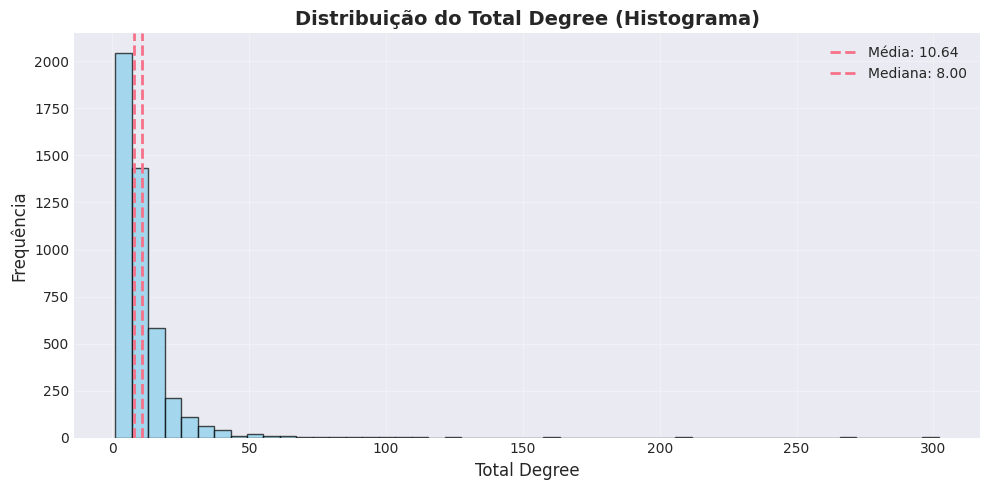

In [27]:
plt.figure(figsize=(10, 5))

plt.hist(df['total_degree'], bins=50, edgecolor='black', alpha=0.7, color='skyblue')
plt.xlabel('Total Degree', fontsize=12)
plt.ylabel('Frequência', fontsize=12)
plt.title('Distribuição do Total Degree (Histograma)', fontsize=14, fontweight='bold')
plt.grid(True, alpha=0.3)

plt.axvline(
    df['total_degree'].mean(),
    linestyle='--',
    linewidth=2,
    label=f'Média: {df["total_degree"].mean():.2f}'
)

plt.axvline(
    df['total_degree'].median(),
    linestyle='--',
    linewidth=2,
    label=f'Mediana: {df["total_degree"].median():.2f}'
)

plt.legend()
plt.tight_layout()
plt.show()


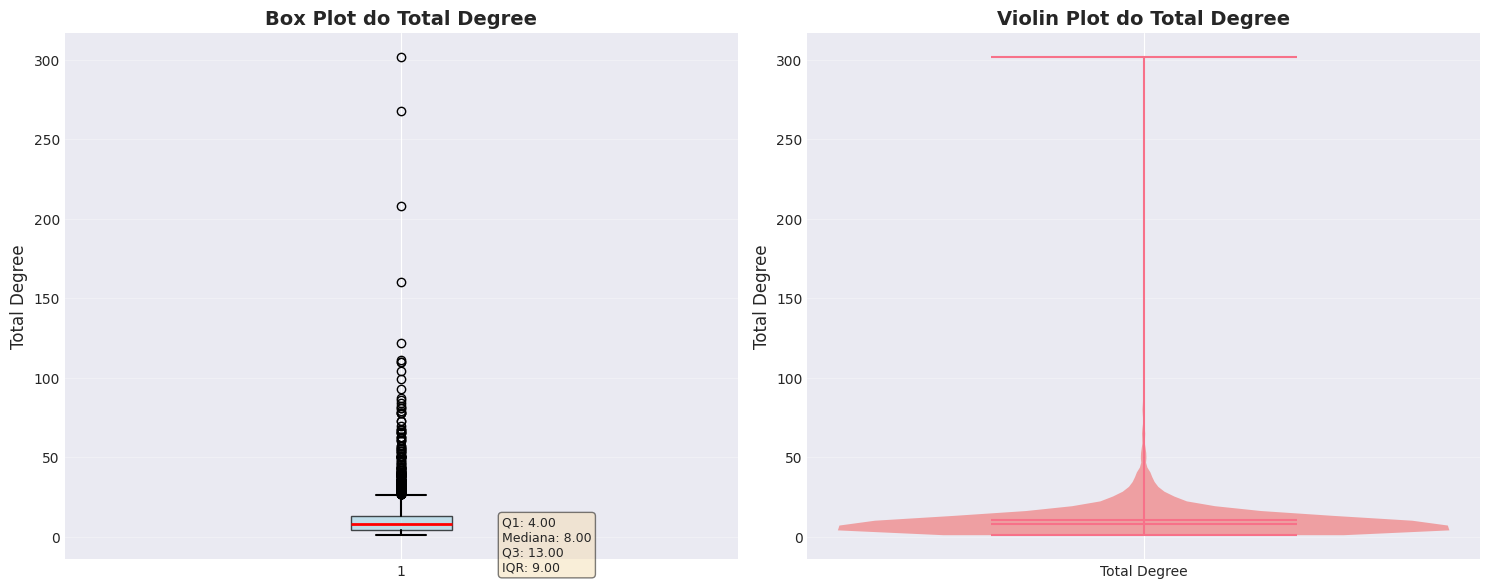

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

bp = axes[0].boxplot(df['total_degree'], vert=True, patch_artist=True, 
                     boxprops=dict(facecolor='lightblue', alpha=0.7),
                     medianprops=dict(color='red', linewidth=2),
                     whiskerprops=dict(color='black', linewidth=1.5),
                     capprops=dict(color='black', linewidth=1.5))
axes[0].set_ylabel('Total Degree', fontsize=12)
axes[0].set_title('Box Plot do Total Degree', fontsize=14, fontweight='bold')
axes[0].grid(True, alpha=0.3, axis='y')

stats_text = f"Q1: {df['total_degree'].quantile(0.25):.2f}\n"
stats_text += f"Mediana: {df['total_degree'].median():.2f}\n"
stats_text += f"Q3: {df['total_degree'].quantile(0.75):.2f}\n"
stats_text += f"IQR: {df['total_degree'].quantile(0.75) - df['total_degree'].quantile(0.25):.2f}"
axes[0].text(1.15, df['total_degree'].quantile(0.75), stats_text, 
             verticalalignment='top', fontsize=9, bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

vp = axes[1].violinplot([df['total_degree']], positions=[1], widths=0.6, 
                        showmeans=True, showmedians=True)
axes[1].set_ylabel('Total Degree', fontsize=12)
axes[1].set_title('Violin Plot do Total Degree', fontsize=14, fontweight='bold')
axes[1].set_xticks([1])
axes[1].set_xticklabels(['Total Degree'])
axes[1].grid(True, alpha=0.3, axis='y')

for pc in vp['bodies']:
    pc.set_facecolor('lightcoral')
    pc.set_alpha(0.7)

plt.tight_layout()
plt.show()


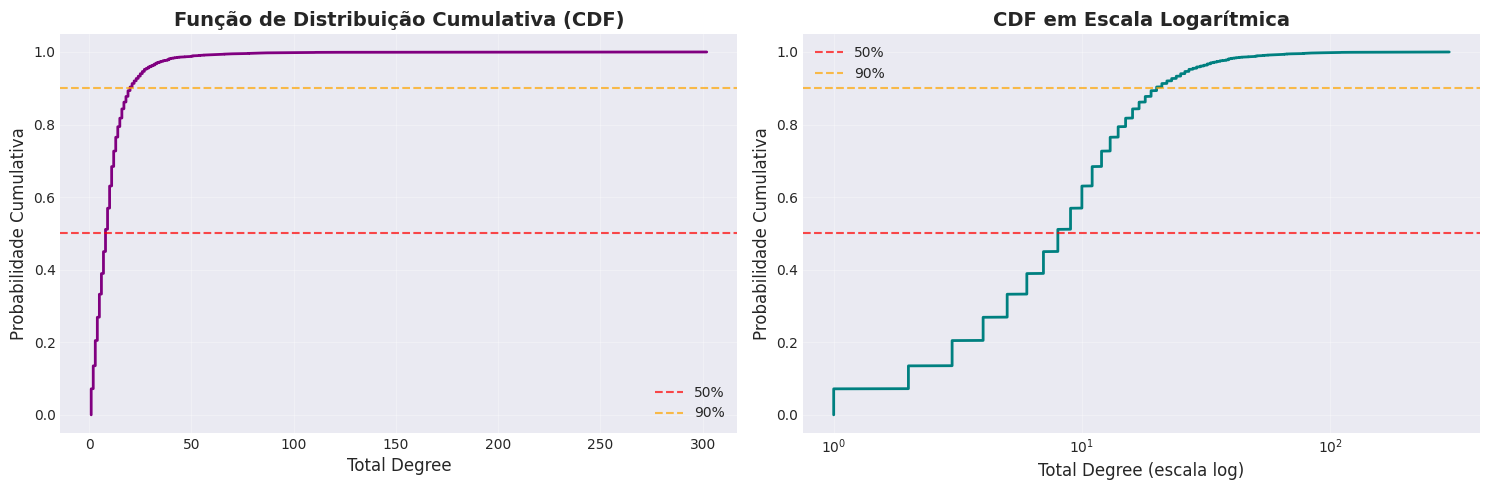

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sorted_degrees = np.sort(df['total_degree'])
cumulative = np.arange(1, len(sorted_degrees) + 1) / len(sorted_degrees)
axes[0].plot(sorted_degrees, cumulative, linewidth=2, color='purple')
axes[0].set_xlabel('Total Degree', fontsize=12)
axes[0].set_ylabel('Probabilidade Cumulativa', fontsize=12)
axes[0].set_title('Função de Distribuição Cumulativa (CDF)', fontsize=14, fontweight='bold')
axes[0].grid(True, alpha=0.3)
axes[0].axhline(0.5, color='red', linestyle='--', alpha=0.7, label='50%')
axes[0].axhline(0.9, color='orange', linestyle='--', alpha=0.7, label='90%')
axes[0].legend()

axes[1].plot(sorted_degrees, cumulative, linewidth=2, color='teal')
axes[1].set_xlabel('Total Degree (escala log)', fontsize=12)
axes[1].set_ylabel('Probabilidade Cumulativa', fontsize=12)
axes[1].set_title('CDF em Escala Logarítmica', fontsize=14, fontweight='bold')
axes[1].set_xscale('log')
axes[1].grid(True, alpha=0.3)
axes[1].axhline(0.5, color='red', linestyle='--', alpha=0.7, label='50%')
axes[1].axhline(0.9, color='orange', linestyle='--', alpha=0.7, label='90%')
axes[1].legend()

plt.tight_layout()
plt.show()


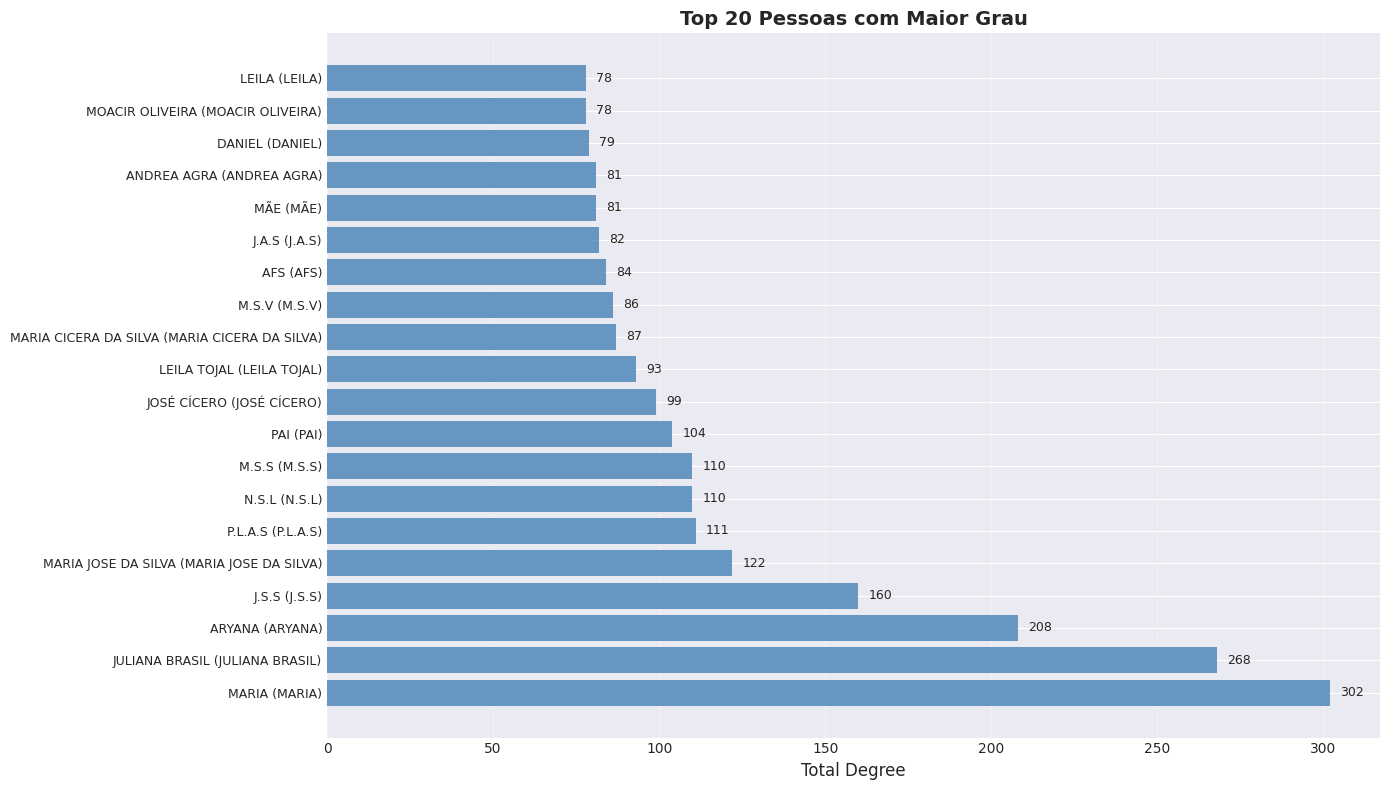

In [36]:
top_20 = df.nlargest(20, 'total_degree')

fig, ax = plt.subplots(figsize=(14, 8))
bars = ax.barh(range(len(top_20)), top_20['total_degree'], color='steelblue', alpha=0.8)
ax.set_yticks(range(len(top_20)))
ax.set_yticklabels([f"{row['person_name']} ({row['title']})" for _, row in top_20.iterrows()], fontsize=9)
ax.set_xlabel('Total Degree', fontsize=12)
ax.set_title('Top 20 Pessoas com Maior Grau', fontsize=14, fontweight='bold')
ax.grid(True, alpha=0.3, axis='x')

for i, (idx, row) in enumerate(top_20.iterrows()):
    ax.text(row['total_degree'] + max(top_20['total_degree']) * 0.01, i, 
            f"{int(row['total_degree'])}", va='center', fontsize=9)

plt.tight_layout()
plt.show()


/tmp/ipykernel_7256/547661425.py:35: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = axes[1].boxplot(data_by_category, labels=categories, patch_artist=True)


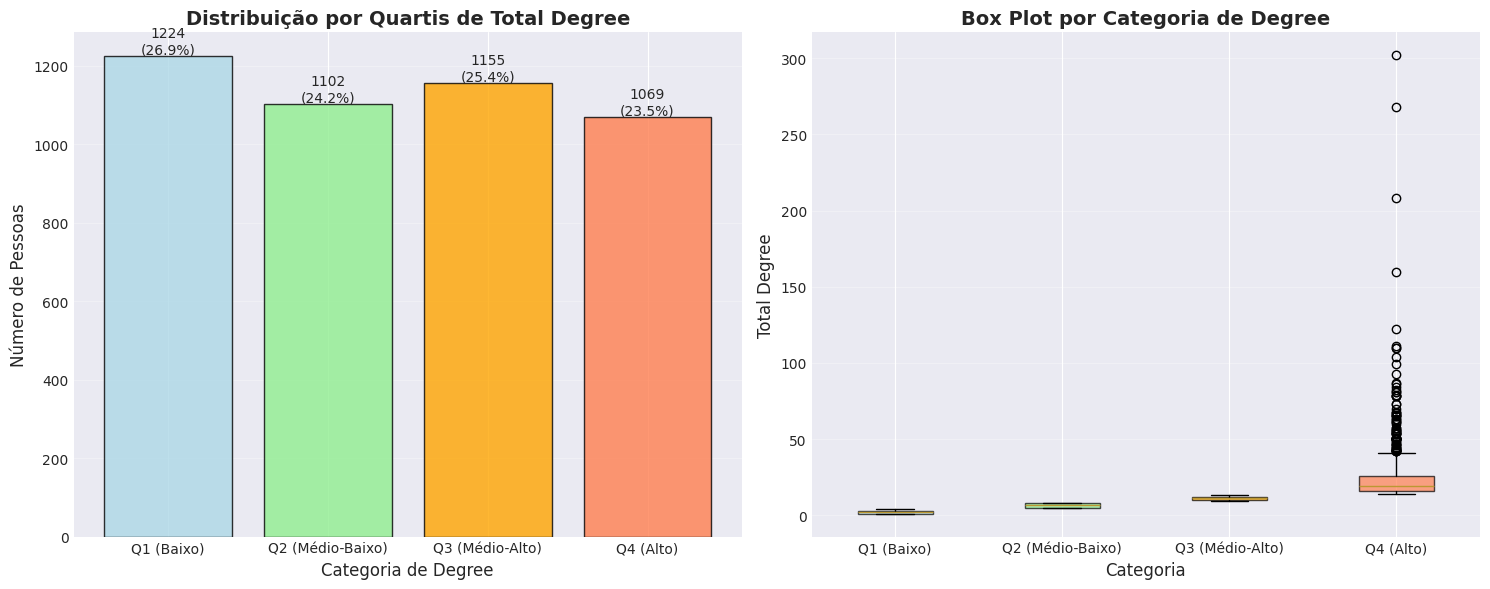


Estatísticas por categoria:


/tmp/ipykernel_7256/547661425.py:52: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  tabela = df.groupby('degree_category')['total_degree'].describe().round(2)


,count,mean,std,min,25%,50%,75%,max
degree_category,,,,,,,,
Q1 (Baixo),1224.0,2.47,1.12,1.0,1.0,2.0,3.0,4.0
Q2 (Médio-Baixo),1102.0,6.49,1.13,5.0,5.0,7.0,8.0,8.0
Q3 (Médio-Alto),1155.0,10.77,1.37,9.0,10.0,11.0,12.0,13.0
Q4 (Alto),1069.0,24.12,18.82,14.0,16.0,19.0,26.0,302.0


In [ ]:
df['degree_category'] = pd.cut(df['total_degree'], 
                                bins=[0, df['total_degree'].quantile(0.25), 
                                      df['total_degree'].quantile(0.5),
                                      df['total_degree'].quantile(0.75), 
                                      df['total_degree'].max()],
                                labels=['Q1 (Baixo)', 'Q2 (Médio-Baixo)', 
                                       'Q3 (Médio-Alto)', 'Q4 (Alto)'])

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

category_counts = df['degree_category'].value_counts().sort_index()
bars = axes[0].bar(category_counts.index, category_counts.values, 
                   color=['lightblue', 'lightgreen', 'orange', 'coral'], 
                   alpha=0.8, edgecolor='black')
axes[0].set_xlabel('Categoria de Degree', fontsize=12)
axes[0].set_ylabel('Número de Pessoas', fontsize=12)
axes[0].set_title('Distribuição por Quartis de Total Degree', fontsize=14, fontweight='bold')
axes[0].grid(True, alpha=0.3, axis='y')

for bar in bars:
    height = bar.get_height()
    axes[0].text(bar.get_x() + bar.get_width()/2., height,
                f'{int(height)}\n({height/len(df)*100:.1f}%)',
                ha='center', va='bottom', fontsize=10)

# Box plot por categoria
df_sorted = df.sort_values('degree_category')
categories = df_sorted['degree_category'].unique()
data_by_category = [df_sorted[df_sorted['degree_category'] == cat]['total_degree'].values 
                    for cat in categories]

bp = axes[1].boxplot(data_by_category, labels=categories, patch_artist=True)
axes[1].set_ylabel('Total Degree', fontsize=12)
axes[1].set_xlabel('Categoria', fontsize=12)
axes[1].set_title('Box Plot por Categoria de Degree', fontsize=14, fontweight='bold')
axes[1].grid(True, alpha=0.3, axis='y')

colors = ['lightblue', 'lightgreen', 'orange', 'coral']
for patch, color in zip(bp['boxes'], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)

plt.tight_layout()
plt.show()

print("\nEstatísticas por categoria:")
tabela = df.groupby('degree_category')['total_degree'].describe().round(2)
display(tabela)




In [45]:
Q1 = df['total_degree'].quantile(0.25)
Q3 = df['total_degree'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[(df['total_degree'] < lower_bound) | (df['total_degree'] > upper_bound)]

print(f"Limite inferior (Q1 - 1.5*IQR): {lower_bound:.2f}")
print(f"Limite superior (Q3 + 1.5*IQR): {upper_bound:.2f}")
print(f"Número de outliers: {len(outliers)} ({len(outliers)/len(df)*100:.2f}%)")


display(
    outliers
        .nlargest(10, 'total_degree')[['person_name', 'title', 'total_degree']]
        .style
        .format({'total_degree': '{:.0f}'})
        .set_caption("Top 10 Outliers por Total Degree")
)



Limite inferior (Q1 - 1.5*IQR): -9.50
Limite superior (Q3 + 1.5*IQR): 26.50
Número de outliers: 245 (5.38%)


,person_name,title,total_degree
0,MARIA,MARIA,302
1,JULIANA BRASIL,JULIANA BRASIL,268
2,ARYANA,ARYANA,208
3,J.S.S,J.S.S,160
4,MARIA JOSE DA SILVA,MARIA JOSE DA SILVA,122
5,P.L.A.S,P.L.A.S,111
6,N.S.L,N.S.L,110
7,M.S.S,M.S.S,110
8,PAI,PAI,104
9,JOSÉ CÍCERO,JOSÉ CÍCERO,99
